# MAKEMORE

### Checking out the names dataset

In [8]:
words = open('names.txt','r').read().splitlines()

In [9]:
words[0:9]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper']

In [10]:
len(words)

32033

In [11]:
#Find min length of word
min(len(w) for w in words)

2

In [12]:
#Find max length of word

In [13]:
max(len(w) for w in words)

15

Training - How it works ? 
- So, in a string like **isabella** ,we have multiple training examples at a character level prediction
- i is a good starting char
- s follows i
- a follows is
- b follows isa
- e follows isab
- l follows isabe
- l follows isabel
- a follows isabell
- "\n" or endChar follows isabella

So this is how the training set looks like for one word

## Implementing Bigram

[Bigram Definition](https://en.wikipedia.org/wiki/Bigram)
- So basically bi meaning 2, the probability that two characters occur together
- Thus, given a single char, what is the next char that occurs
- for isabella this becomes
- i as a start or after the start char
- s after i, a after s, b after a ... endChar after a

The probability of the character increases and that can be used to predict the next character, knowing a singe character before it.

#### Now let's see how data would look like

In [21]:
#For the first 3 words
for w in words[:3]:
    for char1,char2 in zip(w,w[1:]):
        print(char1,char2)
    print("\n") #To separate words

e m
m m
m a


o l
l i
i v
v i
i a


a v
v a




We also need to know what character to start with and when to end
- We can have two special characters \<S> and \<E>
- Now, for \<S> what is the probability distribtion of characters after it
- For, \<E> what is the probability of \<E> after a particular char
- Thus we can have a start symbol \<S>
- And, an end symbol \<E>

In [20]:
#For the first 3 words
for w in words[:3]:
    
    chars = ['<S>'] + list(w) + ['<E>']
    
    for char1, char2 in zip(chars,chars[1:]):
        print(char1,char2)
    
    print("\n")

<S> e
e m
m m
m a
a <E>


<S> o
o l
l i
i v
v i
i a
a <E>


<S> a
a v
v a
a <E>




Now we can store the probability in a dictionary
- Basically counting the combinations of two characters occuring together

In [25]:
#For the first 3 words, but counting and storing in a dictionary

b = {}
for w in words[:3]:
    
    chars = ['<S>'] + list(w) + ['<E>']
    
    for char1, char2 in zip(chars,chars[1:]):
        
        bigram = (char1,char2)
        b[bigram] = b.get(bigram,0)+1
        
b

{('<S>', 'e'): 1,
 ('e', 'm'): 1,
 ('m', 'm'): 1,
 ('m', 'a'): 1,
 ('a', '<E>'): 3,
 ('<S>', 'o'): 1,
 ('o', 'l'): 1,
 ('l', 'i'): 1,
 ('i', 'v'): 1,
 ('v', 'i'): 1,
 ('i', 'a'): 1,
 ('<S>', 'a'): 1,
 ('a', 'v'): 1,
 ('v', 'a'): 1}

Running it for the entire dataset

In [28]:
b = {}
for w in words:
    
    chars = ['<S>'] + list(w) + ['<E>']
    
    for char1, char2 in zip(chars,chars[1:]):
        
        bigram = (char1,char2)
        b[bigram] = b.get(bigram,0)+1

In [29]:
b

{('<S>', 'e'): 1531,
 ('e', 'm'): 769,
 ('m', 'm'): 168,
 ('m', 'a'): 2590,
 ('a', '<E>'): 6640,
 ('<S>', 'o'): 394,
 ('o', 'l'): 619,
 ('l', 'i'): 2480,
 ('i', 'v'): 269,
 ('v', 'i'): 911,
 ('i', 'a'): 2445,
 ('<S>', 'a'): 4410,
 ('a', 'v'): 834,
 ('v', 'a'): 642,
 ('<S>', 'i'): 591,
 ('i', 's'): 1316,
 ('s', 'a'): 1201,
 ('a', 'b'): 541,
 ('b', 'e'): 655,
 ('e', 'l'): 3248,
 ('l', 'l'): 1345,
 ('l', 'a'): 2623,
 ('<S>', 's'): 2055,
 ('s', 'o'): 531,
 ('o', 'p'): 95,
 ('p', 'h'): 204,
 ('h', 'i'): 729,
 ('<S>', 'c'): 1542,
 ('c', 'h'): 664,
 ('h', 'a'): 2244,
 ('a', 'r'): 3264,
 ('r', 'l'): 413,
 ('l', 'o'): 692,
 ('o', 't'): 118,
 ('t', 't'): 374,
 ('t', 'e'): 716,
 ('e', '<E>'): 3983,
 ('<S>', 'm'): 2538,
 ('m', 'i'): 1256,
 ('a', 'm'): 1634,
 ('m', 'e'): 818,
 ('<S>', 'h'): 874,
 ('r', 'p'): 14,
 ('p', 'e'): 197,
 ('e', 'r'): 1958,
 ('r', '<E>'): 1377,
 ('e', 'v'): 463,
 ('v', 'e'): 568,
 ('l', 'y'): 1588,
 ('y', 'n'): 1826,
 ('n', '<E>'): 6763,
 ('b', 'i'): 217,
 ('i', 'g'): 428,


Seeing the most likely combinations in the dataset

In [30]:
sorted(b.items(), key = lambda kv : kv[1], reverse = True)

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

##### A better way to store the data
- a 2D array would be much better
- the rows can be the first character
- the columns the second character
- the values can indicate **the probability that the second character follows the first character**

In [31]:
import torch

By default the datatype is float32, but since we are storing counts we can use int32


In [36]:
a = torch.zeros((3,5))
ab

tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]])

In [37]:
a.dtype

torch.float32

Switching the datatype(dtype) to int32

In [51]:
a = torch.zeros((3,5), dtype = torch.int32)
a

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

In [87]:
a.dtype

torch.int32

Playing/Exploring torch tensors

In [88]:
a[1,3] = 1
a

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, 1]], dtype=torch.int32)

In [89]:
a[2,4] += 1
a

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, 2]], dtype=torch.int32)

#### Making actual data structure
- So we have 26 characters + 2 special characters(\<S> - start, \<E> - end)
- Thus we need a 28x28 tensor

In [90]:
N = torch.zeros((28,28),dtype = torch.int32)
N

tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

#### Adding the counts into 2D Array N

- But we need someway to convert from characters to int for indexing
- So we need a lookup table

In [91]:
#Getting all the characters
#words should have all
chars = sorted(list(set("".join(words))))
chars

['a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

In [92]:
#Now we can create a mapping from s(trings) to i(ntegers)
stoi = {s:i for i,s in enumerate(chars)}
stoi['<S>'] = 26
stoi['<E>'] = 27
stoi

{'a': 0,
 'b': 1,
 'c': 2,
 'd': 3,
 'e': 4,
 'f': 5,
 'g': 6,
 'h': 7,
 'i': 8,
 'j': 9,
 'k': 10,
 'l': 11,
 'm': 12,
 'n': 13,
 'o': 14,
 'p': 15,
 'q': 16,
 'r': 17,
 's': 18,
 't': 19,
 'u': 20,
 'v': 21,
 'w': 22,
 'x': 23,
 'y': 24,
 'z': 25,
 '<S>': 26,
 '<E>': 27}

In [93]:
for w in words:
    
    chars = ['<S>'] + list(w) + ['<E>']
    
    for char1,char2 in zip(chars,chars[1:]): 
        
        N[stoi[char1],stoi[char2]] +=1
        
N

tensor([[ 556,  541,  470, 1042,  692,  134,  168, 2332, 1650,  175,  568, 2528,
         1634, 5438,   63,   82,   60, 3264, 1118,  687,  381,  834,  161,  182,
         2050,  435,    0, 6640],
        [ 321,   38,    1,   65,  655,    0,    0,   41,  217,    1,    0,  103,
            0,    4,  105,    0,    0,  842,    8,    2,   45,    0,    0,    0,
           83,    0,    0,  114],
        [ 815,    0,   42,    1,  551,    0,    2,  664,  271,    3,  316,  116,
            0,    0,  380,    1,   11,   76,    5,   35,   35,    0,    0,    3,
          104,    4,    0,   97],
        [1303,    1,    3,  149, 1283,    5,   25,  118,  674,    9,    3,   60,
           30,   31,  378,    0,    1,  424,   29,    4,   92,   17,   23,    0,
          317,    1,    0,  516],
        [ 679,  121,  153,  384, 1271,   82,  125,  152,  818,   55,  178, 3248,
          769, 2675,  269,   83,   14, 1958,  861,  580,   69,  463,   50,  132,
         1070,  181,    0, 3983],
        [ 242,    0,

- We can see last row is compeletely empty
- This validates that after \<E> end character no other character comes

#### Plotting using matplotlib for better visualization

In [94]:
import matplotlib.pyplot as plt
%matplotlib inline

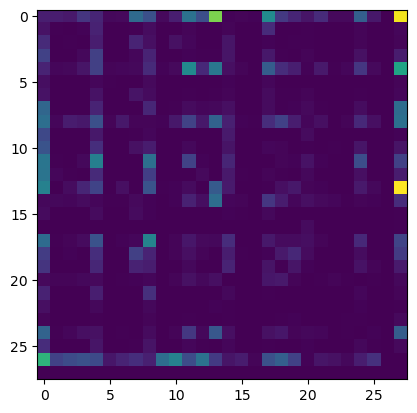

In [95]:
plt.imshow(N)

- Still looking ugly?
- Let's making it really beautiful

In [96]:
#Integer to string mapping
itos = {i:s for s,i in stoi.items()}
itos

{0: 'a',
 1: 'b',
 2: 'c',
 3: 'd',
 4: 'e',
 5: 'f',
 6: 'g',
 7: 'h',
 8: 'i',
 9: 'j',
 10: 'k',
 11: 'l',
 12: 'm',
 13: 'n',
 14: 'o',
 15: 'p',
 16: 'q',
 17: 'r',
 18: 's',
 19: 't',
 20: 'u',
 21: 'v',
 22: 'w',
 23: 'x',
 24: 'y',
 25: 'z',
 26: '<S>',
 27: '<E>'}

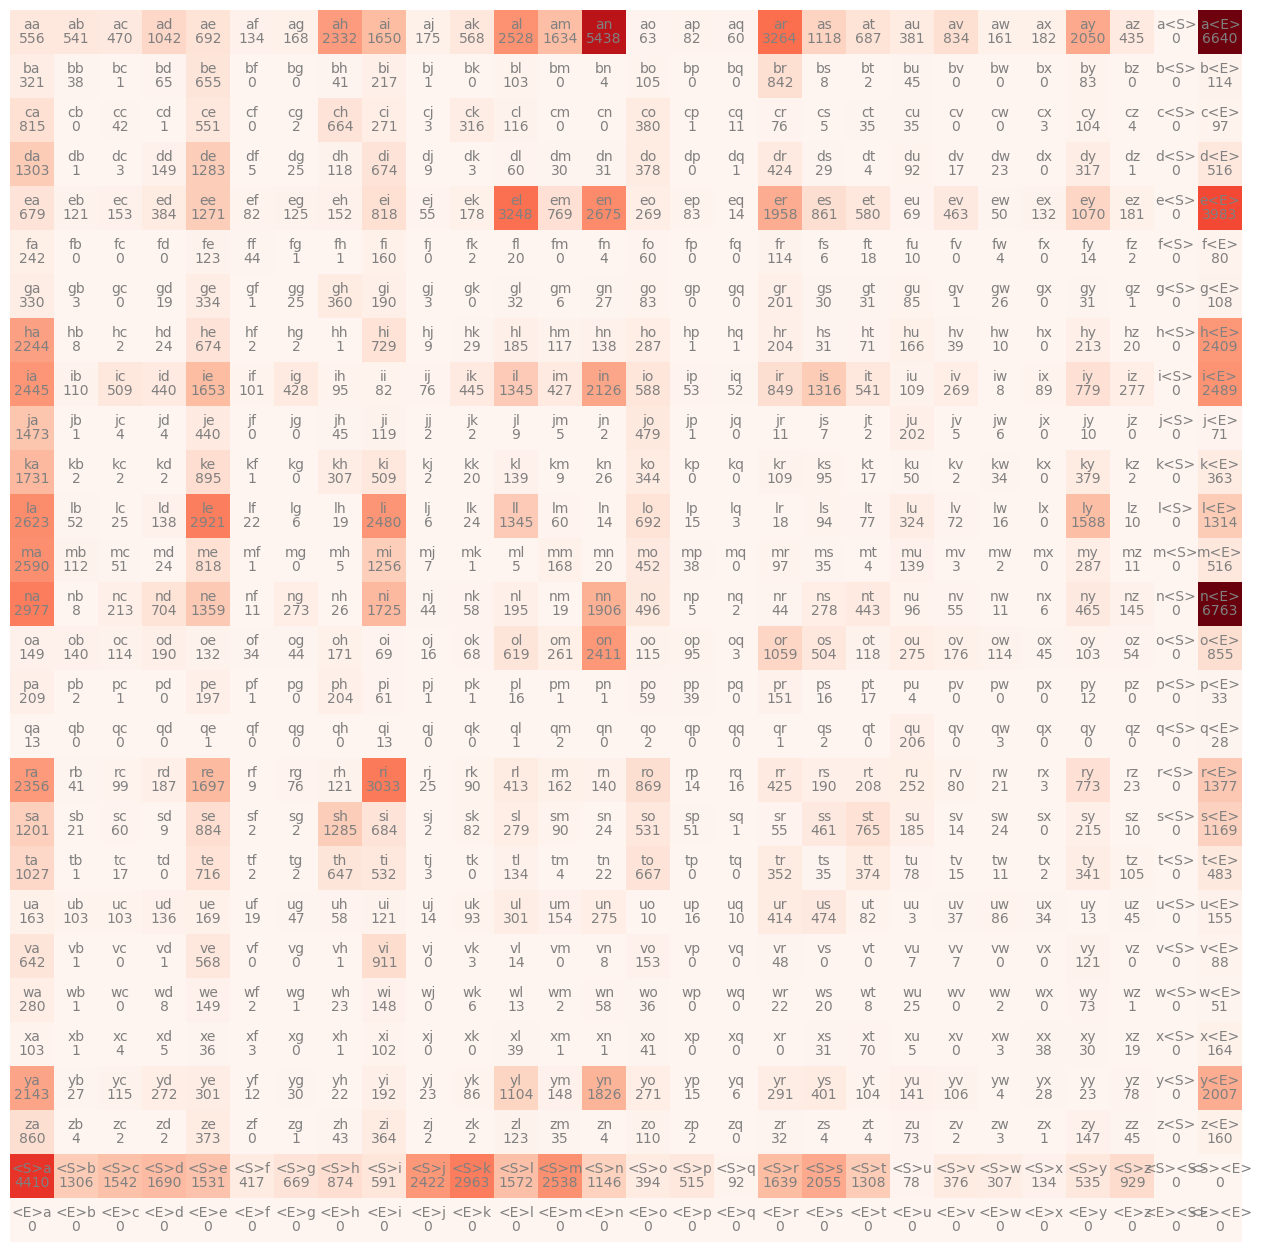

In [97]:
plt.figure(figsize = (16,16))
plt.imshow(N,cmap = 'Reds')
for i in range(28):
    for j in range(28):
        chstr = itos[i] + itos[j]
        plt.text(j,i,chstr,ha="center",va="bottom",color="grey") #Show the bigram
        plt.text(j,i,N[i,j].item(),ha="center",va="top",color="grey") #Show the count
plt.axis('off');

#### Observations
- Last row is completely 0
- Because endChar \<E> can never be first or start character
- Second Lasy column is completely 0
- Because startChar \<S> can never be second or end character
- \<S>\<S> and \<E>\<E> are both 0
- \<S>\<E> can only be 0 for an empty word which is why it is zero
- \<E>\<S> is never possible so again 0

### To optimise
- We can have . as a special character, \<S> and \<E> take too much space
- Having it as same helps to reduce the redundant cells due to special properties
- Since both \<S> and \<E> have special properties which ensure 1 entire row and 1 entire column to be 0
- Also 3 of the 4 cases are always 0, and 1 case is only possible for empty word
- So all 4 cases are 0, so not an issue, if we collapse it there

In [99]:
#Getting all the characters
#words should have all
chars = sorted(list(set("".join(words))))
chars

['a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

In [100]:
#Having the special character as 0th position just feels better
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
stoi

{'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26,
 '.': 0}

In [129]:
itos = {i:s for s,i in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

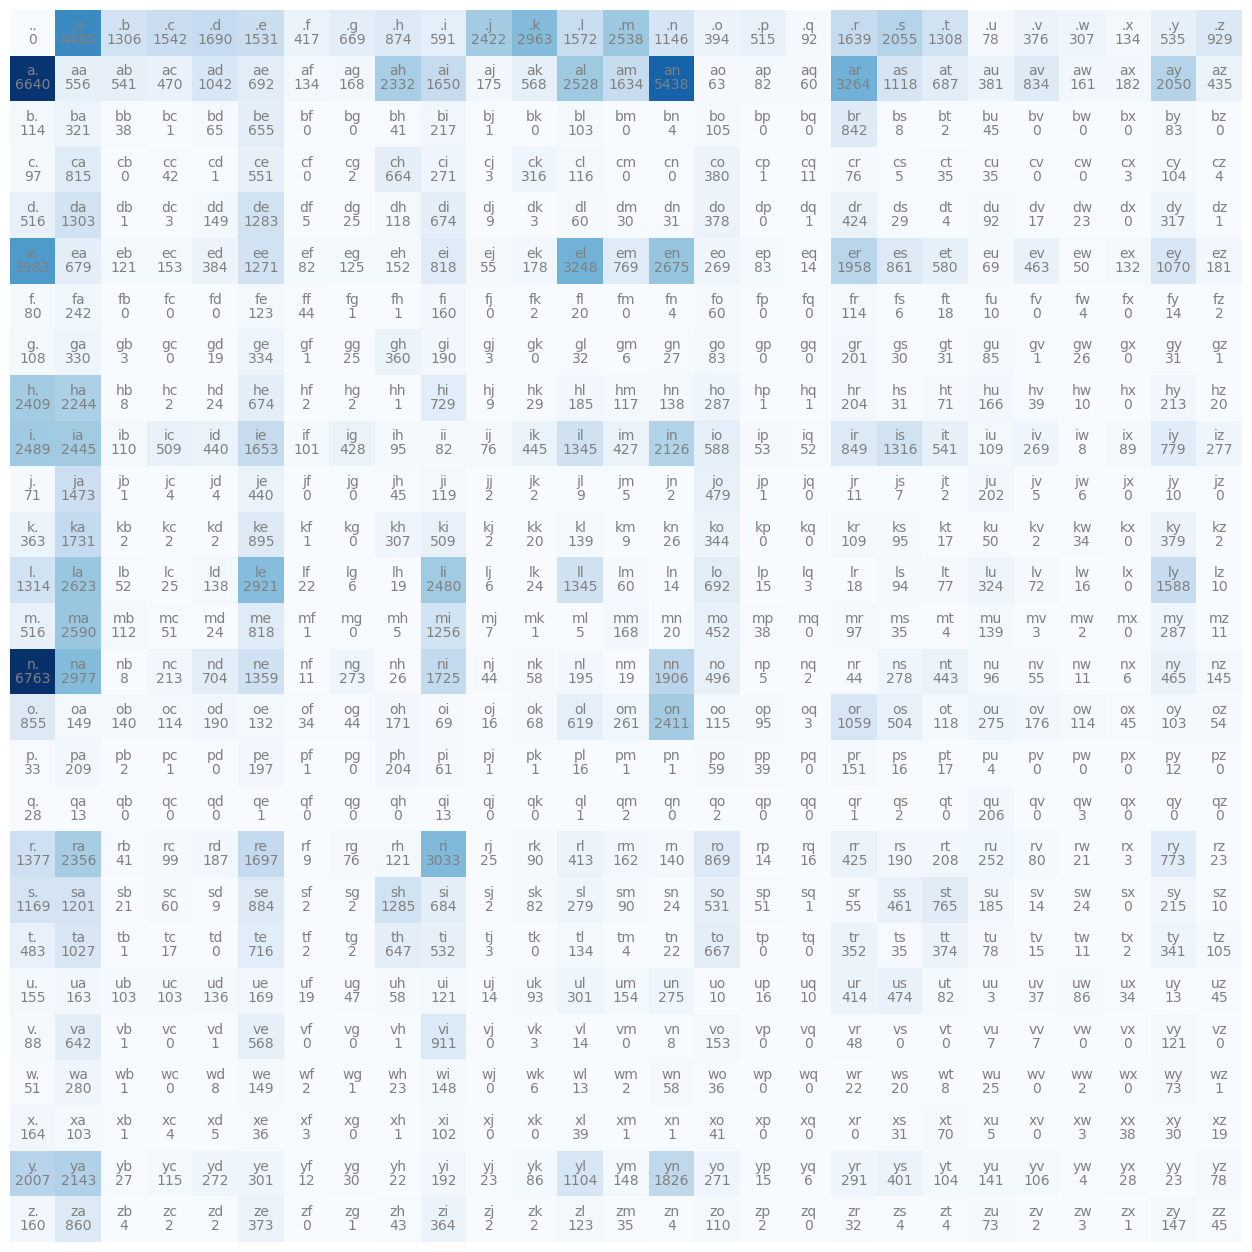

In [130]:
N = torch.zeros((27,27),dtype = torch.int32)
for w in words:
    
    chars = ['.'] + list(w) + ['.']
    
    for char1,char2 in zip(chars,chars[1:]): 
        
        N[stoi[char1],stoi[char2]] +=1
        
plt.figure(figsize = (16,16))
plt.imshow(N,cmap = 'Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j,i,chstr,ha="center",va="bottom",color="grey") #Show the bigram
        plt.text(j,i,N[i,j].item(),ha="center",va="top",color="grey") #Show the count
plt.axis('off');

#### Raw counts need to be converted to probability
- We have raw counts as of now of each bigram
- We need it as a probability distribution

In [131]:
N[0]

tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

In [132]:
#We just need to divide by the sum
# That may be in float, so let's convert everything to float
p = N[0].float()
p  = p/p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

- [PyTorch Multinomial](https://docs.pytorch.org/docs/2.15/generated/torch.multinomial.html)
- [Multinomial Distribution](https://en.wikipedia.org/wiki/Multinomial_distribution)
- So, basically a distribution get's created based on our probabilites
- The probabilities of the bigram for which char comes next
- That is a multinomial distribution
- Now PyTorch Multinomial helps sample/pick a number by following that distribution
- This allows to randomly sample and find out next char to predict
- But also follow the probability distribution so it feels like a real name

- [PyTorch Generator](https://docs.pytorch.org/docs/2.15/generated/torch.Generator.html)
- Make the picking process deterministic
- So the results that I get, a replicated copy of this will also get the same results
- So validation is made easier, as there is no other better known method of validation

In [133]:
#We can keep running this cell and the values won't change
g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3,generator = g)
p

tensor([0.7081, 0.3542, 0.1054])

In [134]:
#Getting Porbability Distribution
p = p/p.sum()
p

tensor([0.6064, 0.3033, 0.0903])

Trying out multinomial distribution in python

In [135]:
torch.multinomial(p,num_samples = 100,replacement = True,generator = g)

tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 2, 0, 0,
        1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1,
        0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 1, 0, 0, 2, 0, 1, 0,
        0, 1, 1, 1])

- Thus, if we check approximately, the counts of each number are approximately same to their probability distribution.
- The number of 0's are approximately double of 1's (0.6064 ~ 0.3033*2)
- The number of 1's are approximately triple the 2's (0.3033 ~ 0.0903*3)

Now let's sample from it as desired to predict the next character using bigram

In [136]:
p = N[0].float()
p  = p/p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [137]:
g = torch.Generator().manual_seed(2147483647)
torch.multinomial(p,num_samples = 1,replacement = True,generator = g)

tensor([3])


We can see the type is tensor but we need it to be int, so we can use .item()

In [138]:
torch.multinomial(p,num_samples = 1,replacement = True,generator = g).item()

5

- Now, we can convert that to character
- So we need interger to string
- So itos lookup table is there

In [140]:
ix = torch.multinomial(p,num_samples = 1,replacement = True,generator = g).item()
itos[ix]

'b'

#### Now we have the parts
- We can just write out the loop
- So we start with index(ix) as 0, cuz starting char is .
- Then get probability(p) of that from N our 2D array
- So basically just N[ix]
- and just divide by sum to get probability
- From this we can sample a number, and itos to char
- print that char,
- and if ., that means end char so stop or break
- we can do this infinitely till we get end char or .

In [147]:
g = torch.Generator().manual_seed(2147483647)

outArr = []
ix = 0

while True:
    p = N[ix]
    p = p/p.sum()
    ix = torch.multinomial(p,num_samples = 1,replacement = True,generator = g).item()
    if ix==0:
        break
    outArr.append(itos[ix])

output = "".join(outArr)
print(output)

cexze


## What an untrained model would give us
- So we can just keep p as a normal uniform distribution

In [153]:
g = torch.Generator().manual_seed(2147483648)

for i in range(10):

    outArr = []
    ix = 0

    while True:
        
        p = torch.ones(27) / 27.0
        
        ix = torch.multinomial(p,num_samples = 1,replacement = True,generator = g).item()
        if ix==0:
            break
        outArr.append(itos[ix])

    output = "".join(outArr)
    print(output)

xrbhfevny
zhuotdejevyuxsuqbkmmdzttugmre
ulscwfs
xyawmtdqbpzwrfedxnnqhouqqtlme

mmtasgiyuqzssxzdcpeovuuiqmexmnnykxzuvnlldvqdghtxvrptgokte
dtjhgkbu
qyyahawmvfycdhc
mlpepbqgxvlmpalfspluswawcvdcwbodyhofssuhqwlxvt
hcutluhhumsnskinyf


## What a model trained on bigram gives us
- So we can set our p to a multinomial distribution that we learned from our names.txt dataset

In [154]:
g = torch.Generator().manual_seed(2147483648)

for i in range(10):

    outArr = []
    ix = 0

    while True:
        
        p = N[ix]
        p = p/p.sum()
        
        ix = torch.multinomial(p,num_samples = 1,replacement = True,generator = g).item()
        if ix==0:
            break
        outArr.append(itos[ix])

    output = "".join(outArr)
    print(output)

iri
kevny
zisoudeeen
cosheromydan
be
re
jusowes
kya
madethewrierinn
jouretone


Thus, we can see the model is working and it is more name like

## Optimisation
- We are at every step having to normalise by the row sum
- This can be precomputed and stored earlier
- So we need to have the probabilites instead of the counts
- This can be done using tensor manipulation
- [PyTorch Sum](https://docs.pytorch.org/docs/2.15/generated/torch.sum.html)

In [156]:
P = N.float()
P.sum()

tensor(228146.)

In [158]:
P.shape

torch.Size([27, 27])

- So we need to sum every single row, and not columns
- torch.sum(input, dim, keepdim=False, *, dtype=None)
- So row is dim 0 and col is dim 1, 
- Now a row contains all columns, so all columns need to be added for a single row
- For e.g. a 3x3 grid
- so row 0 has -> (0,0) (0,1) (0,2) -> all columns need to be added, row 0 is kept constant
- thus we need to sum all columns
- thus we need to sum dim 1

In [171]:
P.sum(1,keepdim = True)

tensor([[32033.],
        [33885.],
        [ 2645.],
        [ 3532.],
        [ 5496.],
        [20423.],
        [  905.],
        [ 1927.],
        [ 7616.],
        [17701.],
        [ 2900.],
        [ 5040.],
        [13958.],
        [ 6642.],
        [18327.],
        [ 7934.],
        [ 1026.],
        [  272.],
        [12700.],
        [ 8106.],
        [ 5570.],
        [ 3135.],
        [ 2573.],
        [  929.],
        [  697.],
        [ 9776.],
        [ 2398.]])

- Thus, we have a column vector
- All rows have been collapsed to their sum value into a single number

In [172]:
P.sum(1,keepdim = True).shape

torch.Size([27, 1])

- So we have summed every single row
- Thus each row collapses to a single number, it's sum
- Hence \[27,27\] -> \[27,1\] 

In [173]:
P.sum(1,keepdim = False)

tensor([32033., 33885.,  2645.,  3532.,  5496., 20423.,   905.,  1927.,  7616.,
        17701.,  2900.,  5040., 13958.,  6642., 18327.,  7934.,  1026.,   272.,
        12700.,  8106.,  5570.,  3135.,  2573.,   929.,   697.,  9776.,  2398.])

In [174]:
P.sum(1,keepdim = False).shape

torch.Size([27])

- If we put keepdim = True, we retain that dimension, but it's get compressed to one value
- So we get a 2D tensor - 1x27
- If we put keepdim = False, we do not retain that dimension anymore
- So we get a 1D tensor of 27 values

### Broadcasting
- [Broadcasting Semantics](https://docs.pytorch.org/docs/2.15/notes/broadcasting.html#broadcasting-semantics)
- We have P which is a 27 x 27 tensor
- But when we do P.sum(1,keepdim = True), we have 27 x 1 tensor
- So how do we divide 27 x 27 tensor by 27 x 1 tensor
- That is explained by broadcasting semantics
- When iterating over the dimension sizes, starting at the trailing dimension, the dimension sizes must either be equal, one of them is 1, or one of them does not exist.

In [176]:
P = N.float()
P = P / P.sum(1,keepdim = True)

- This is broadcastable as
- P = 27 x 27
- P.sum(1,keepdim = True) = 27 x 1
- So for the first part both 27 are
equal
- For the second part one of the dimension is 1

In [178]:
P.shape

torch.Size([27, 27])

In [179]:
P

tensor([[0.0000e+00, 1.3767e-01, 4.0770e-02, 4.8138e-02, 5.2758e-02, 4.7794e-02,
         1.3018e-02, 2.0885e-02, 2.7284e-02, 1.8450e-02, 7.5610e-02, 9.2498e-02,
         4.9074e-02, 7.9231e-02, 3.5776e-02, 1.2300e-02, 1.6077e-02, 2.8720e-03,
         5.1166e-02, 6.4153e-02, 4.0833e-02, 2.4350e-03, 1.1738e-02, 9.5839e-03,
         4.1832e-03, 1.6702e-02, 2.9001e-02],
        [1.9596e-01, 1.6408e-02, 1.5966e-02, 1.3870e-02, 3.0751e-02, 2.0422e-02,
         3.9546e-03, 4.9579e-03, 6.8821e-02, 4.8694e-02, 5.1645e-03, 1.6763e-02,
         7.4605e-02, 4.8222e-02, 1.6048e-01, 1.8592e-03, 2.4199e-03, 1.7707e-03,
         9.6326e-02, 3.2994e-02, 2.0274e-02, 1.1244e-02, 2.4613e-02, 4.7514e-03,
         5.3711e-03, 6.0499e-02, 1.2838e-02],
        [4.3100e-02, 1.2136e-01, 1.4367e-02, 3.7807e-04, 2.4575e-02, 2.4764e-01,
         0.0000e+00, 0.0000e+00, 1.5501e-02, 8.2042e-02, 3.7807e-04, 0.0000e+00,
         3.8941e-02, 0.0000e+00, 1.5123e-03, 3.9698e-02, 0.0000e+00, 0.0000e+00,
         3.1834e-

In [180]:
P[0].sum()

tensor(1.)

- Since, we now have probability
- Each row sum should be 1

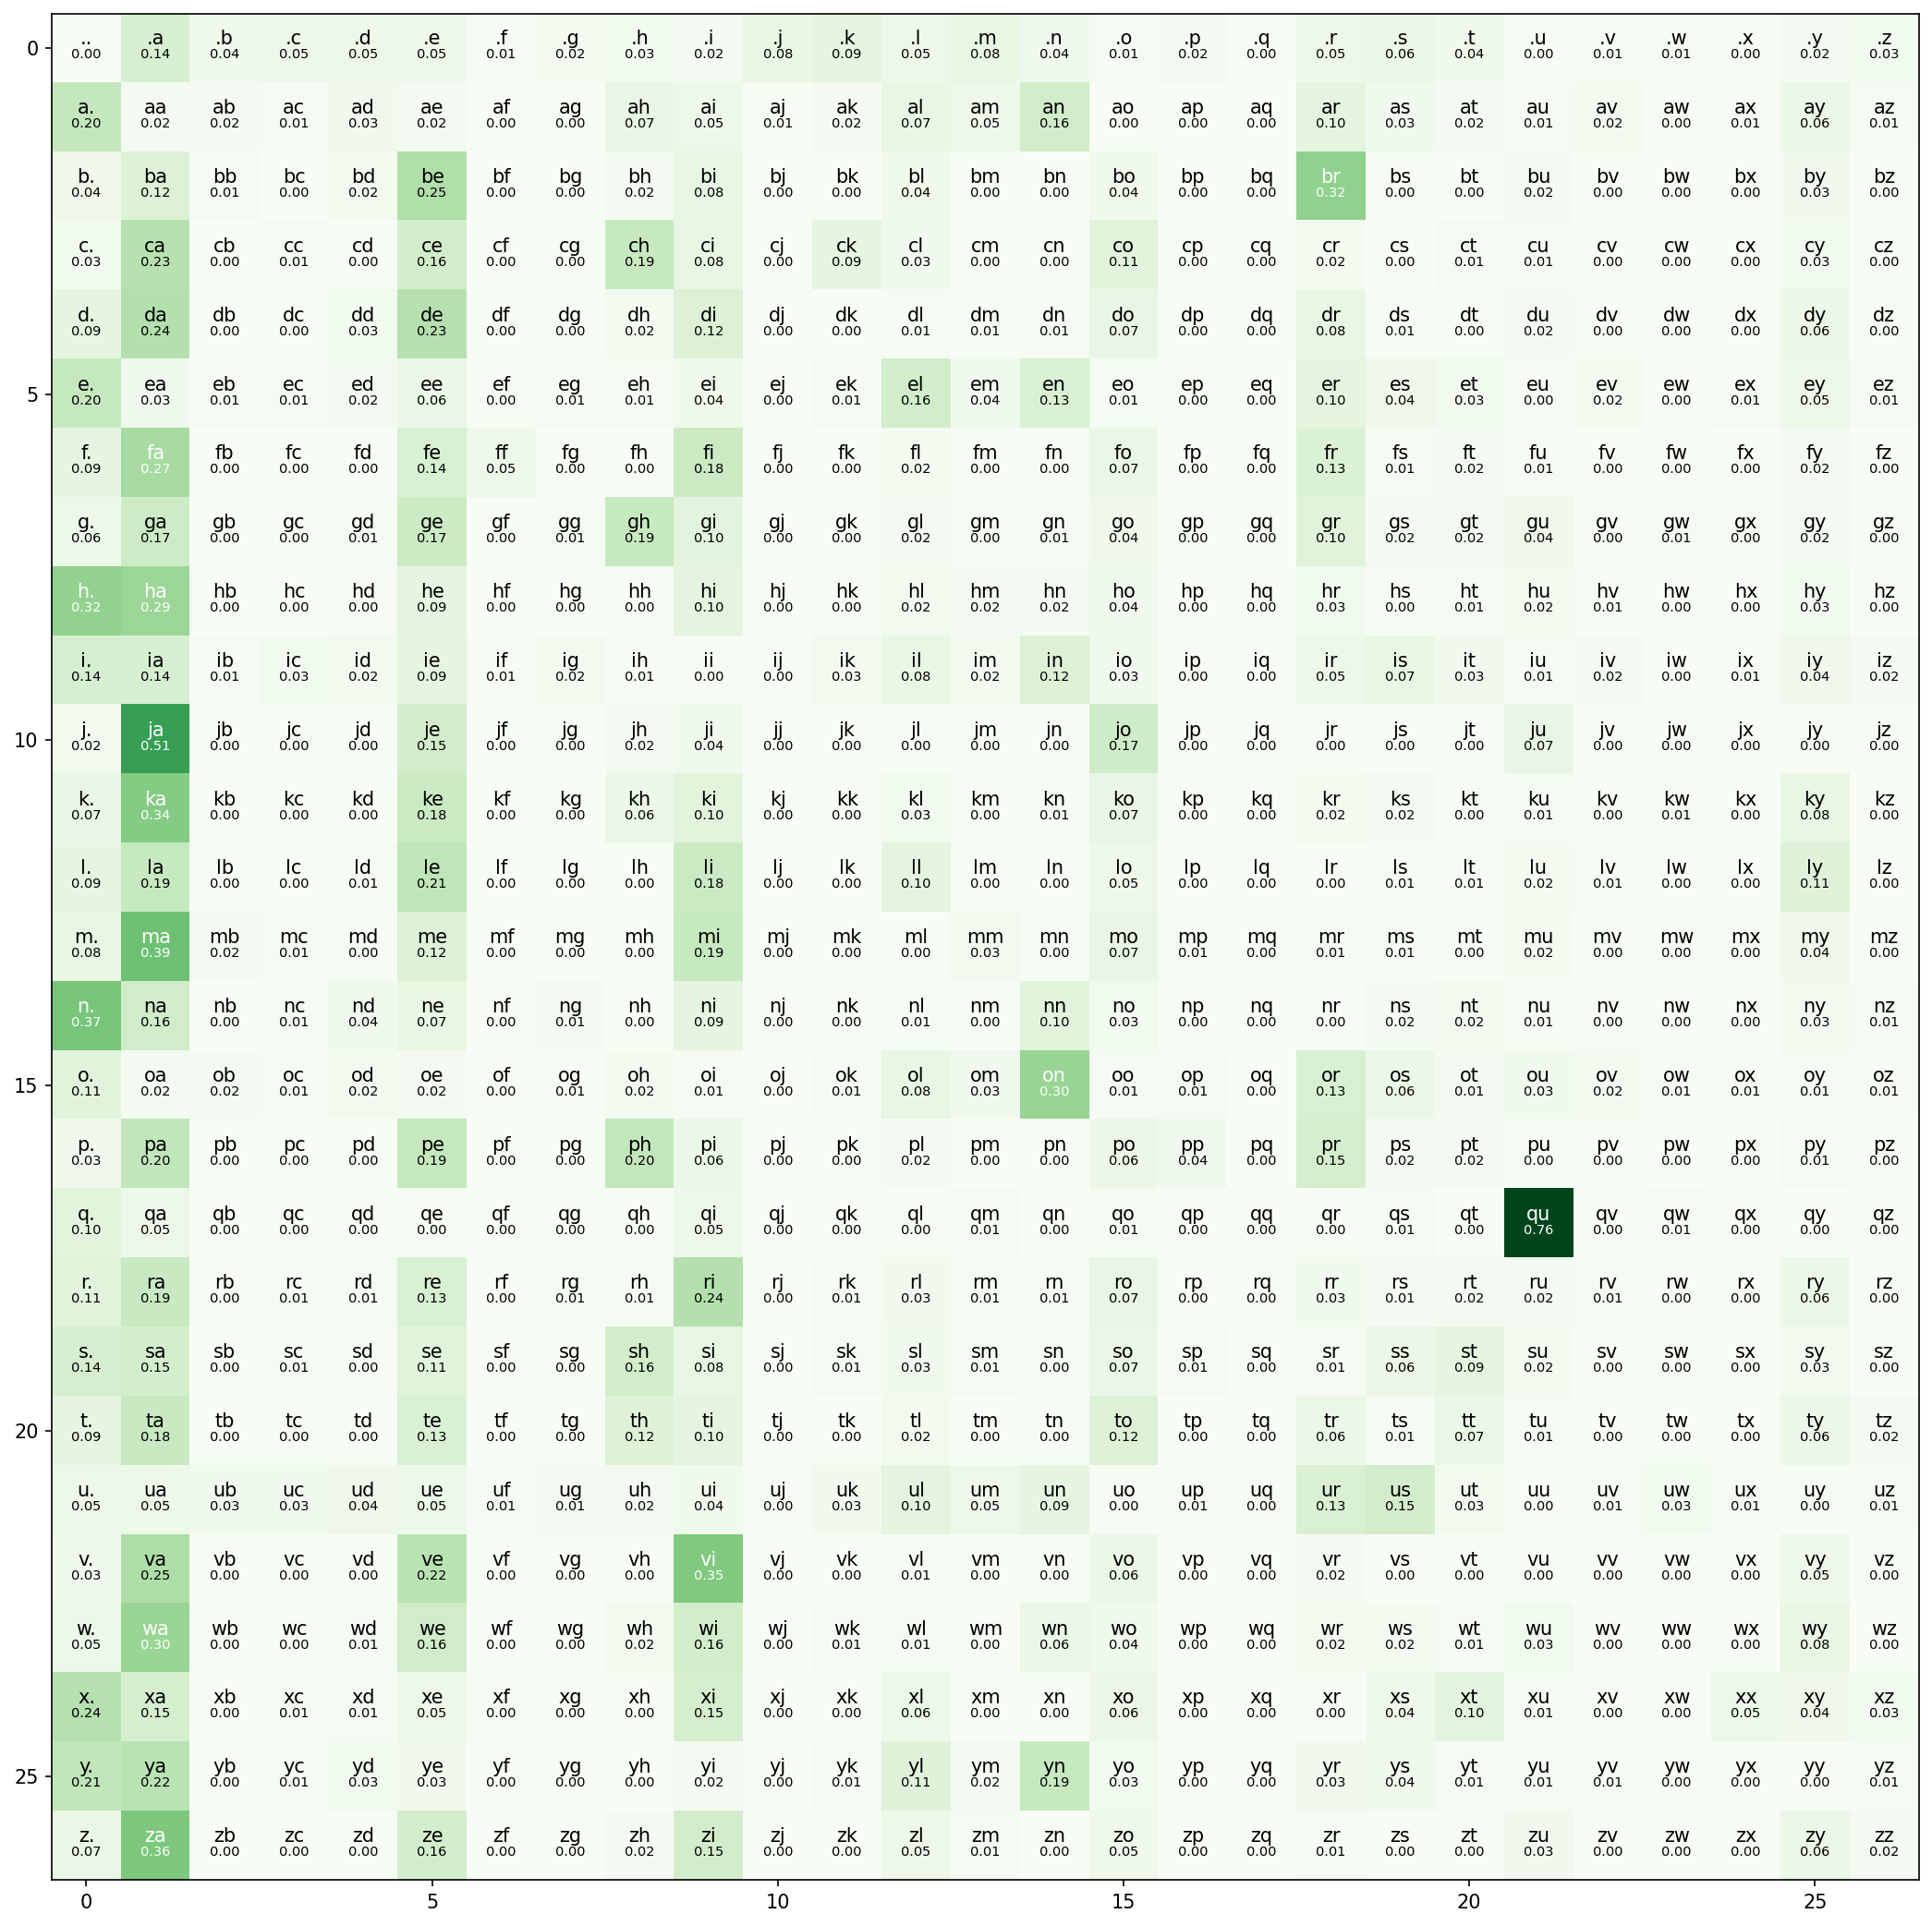

In [195]:
#See it visually
plt.figure(figsize=(16, 14), dpi=150)
plt.imshow(P, cmap="Greens", interpolation="nearest")
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j,i,chstr,ha="center",va="bottom",color="black" if P[i, j] < 0.25 else "white") #Show the bigram
        plt.text(
            j, i,
            f"{P[i, j]:.2f}",
            ha="center",
            va="top",
            fontsize=7,
            color="black" if P[i, j] < 0.25 else "white"
        ) #Show the probability
plt.tight_layout()
plt.show()

- Now we can use P instead of N

#### Non optimised Version
- Using N instead of P

In [225]:
g = torch.Generator().manual_seed(2147483648)

for i in range(10):

    outArr = []
    ix = 0

    while True:
        
        p = N[ix]
        p = p / p.sum()
        
        ix = torch.multinomial(p,num_samples = 1,replacement = True,generator = g).item()
        if ix==0:
            break
        outArr.append(itos[ix])

    output = ''.join(outArr)
    print(output)

iri
kevny
zisoudeeen
cosheromydan
be
re
jusowes
kya
madethewrierinn
jouretone


#### Optimised Version
- Using P instead of N

In [227]:
P = N.float()
P = P / P.sum(1,keepdim = True)

g = torch.Generator().manual_seed(2147483648)

for i in range(10):

    outArr = []
    ix = 0

    while True:
        
        p = P[ix]
        
        ix = torch.multinomial(p,num_samples = 1,replacement = True,generator = g).item()
        if ix==0:
            break
        outArr.append(itos[ix])

    output = ''.join(outArr)
    print(output)

iri
kevny
zisoudeeen
cosheromydan
be
re
jusowes
kya
madethewrierinn
jouretone


- We see that this will give the same result as the earlier non optimised version
- Since, we just converted the counts to probabilities

## Setting up Eval
- So we need to be able to measure how well is the model performing
- So we need to be able to measure the training loss

In [229]:
for w in words[:3]:
    
    chars = ['.'] + list(w) + ['.']
    
    for char1,char2 in zip(chars,chars[1:]): 
        
        ix1 = stoi[char1]
        ix2 = stoi[char2]
        prob = P[ix1,ix2]
        print(f"{char1}{char2} : {prob:.4f}")
    

.e : 0.0478
em : 0.0377
mm : 0.0253
ma : 0.3899
a. : 0.1960
.o : 0.0123
ol : 0.0780
li : 0.1777
iv : 0.0152
vi : 0.3541
ia : 0.1381
a. : 0.1960
.a : 0.1377
av : 0.0246
va : 0.2495
a. : 0.1960


- Doing normal statistics
- We have 27 values per row
- So as per uniform distribution,
- probability per cell should be 1/27 ~ 0.037
- so 3.7%
- but we can see combinations such as 'ma' having probability of 38.99%
- so the model evaluates that very highly

### How to measure loss
- For this we use
- [Maximum likelihood estimation](https://en.wikipedia.org/wiki/Maximum_likelihood_estimation)
- So, we have to plot a distribution, to the given multinomial distribution we get in P
- Now, for this distribution we try to plot points, and our goal is to get them exactly right
- So let's say the point 'ma' is at 0.3899 we need to fit a distribution
- that plots the point there, and the difference we try to measure on a scale of 0 to 1
- 1 means perfectly correct, and 0 means very wrong or off
- Thus, this helps us measure a loss
- Now, usually for error or loss in likelihood me multiply the prob values
- But since the values are between 0 and 1 the value becomes very small so we need to fix that
- This is solved by using [log likelihood](https://web.stanford.edu/class/archive/cs/cs109/cs109.1206/lectureNotes/LN20_parameters_mle.pdf)
- This helps because
- log(a\*b\*c) = log(a) + log(b) + log(c)
- So we just end up adding and also, 
- log(1) is just 0
- log(0) is -infinity
- thus, as we move from 1 which we want; to 0 which we don't want,
- the value increases in the negative domain, which helps us tell the loss
- thus, we can tell how well the model performs

In [233]:
for w in words[:3]:
    
    chars = ['.'] + list(w) + ['.']
    
    for char1,char2 in zip(chars,chars[1:]): 
        
        ix1 = stoi[char1]
        ix2 = stoi[char2]
        prob = P[ix1,ix2]
        log_prob = torch.log(prob)
        print(f"{char1}{char2} : {prob:.4f} : {log_prob:.4f}")
    

.e : 0.0478 : -3.0408
em : 0.0377 : -3.2793
mm : 0.0253 : -3.6772
ma : 0.3899 : -0.9418
a. : 0.1960 : -1.6299
.o : 0.0123 : -4.3982
ol : 0.0780 : -2.5508
li : 0.1777 : -1.7278
iv : 0.0152 : -4.1867
vi : 0.3541 : -1.0383
ia : 0.1381 : -1.9796
a. : 0.1960 : -1.6299
.a : 0.1377 : -1.9829
av : 0.0246 : -3.7045
va : 0.2495 : -1.3882
a. : 0.1960 : -1.6299


- We can see that for large values('ma') such as 0.3899 -> log prob is -0.9418
- While for smaller values ('mm') such as 0.0253 -> log prob is -3.6772
- As the closer the prob values are to 1, and the closer the log prob values are to 0
- It is better, as the overall loss drops, which indicates a better model
- Thus, we can sum up all the log prob values to indicate our total loss
- This, works out because in maximum likelihood estimation we multiply the values
- But log has a property
- log(a\*b\*c) = log(a) + log(b) + log(c)
- Thus, this helps us set up eval for the model by estimating the loss

In [234]:
log_likelihood = 0.0

for w in words[:3]:
    
    chars = ['.'] + list(w) + ['.']
    
    for char1,char2 in zip(chars,chars[1:]): 
        
        ix1 = stoi[char1]
        ix2 = stoi[char2]
        prob = P[ix1,ix2]
        log_prob = torch.log(prob)
        log_likelihood += log_prob
        print(f"{char1}{char2} : {prob:.4f} : {log_prob:.4f}")
        
print(f'log likelihood : {log_likelihood:.4f}')

.e : 0.0478 : -3.0408
em : 0.0377 : -3.2793
mm : 0.0253 : -3.6772
ma : 0.3899 : -0.9418
a. : 0.1960 : -1.6299
.o : 0.0123 : -4.3982
ol : 0.0780 : -2.5508
li : 0.1777 : -1.7278
iv : 0.0152 : -4.1867
vi : 0.3541 : -1.0383
ia : 0.1381 : -1.9796
a. : 0.1960 : -1.6299
.a : 0.1377 : -1.9829
av : 0.0246 : -3.7045
va : 0.2495 : -1.3882
a. : 0.1960 : -1.6299
log likelihood : -38.7856


- But due, to the semantics or understanding of a loss function
- We are trying to minimise the loss always
- Thus we can just invert or negate the log likelihood
- This, gives us nll -> negative log likelihood

In [235]:
log_likelihood = 0.0

for w in words[:3]:
    
    chars = ['.'] + list(w) + ['.']
    
    for char1,char2 in zip(chars,chars[1:]): 
        
        ix1 = stoi[char1]
        ix2 = stoi[char2]
        prob = P[ix1,ix2]
        log_prob = torch.log(prob)
        log_likelihood += log_prob
        print(f"{char1}{char2} : {prob:.4f} : {log_prob:.4f}")
        
print(f'log likelihood : {log_likelihood:.4f}')

#Negative Log Likelihood
nll = -log_likelihood
print(f'{nll=}')

.e : 0.0478 : -3.0408
em : 0.0377 : -3.2793
mm : 0.0253 : -3.6772
ma : 0.3899 : -0.9418
a. : 0.1960 : -1.6299
.o : 0.0123 : -4.3982
ol : 0.0780 : -2.5508
li : 0.1777 : -1.7278
iv : 0.0152 : -4.1867
vi : 0.3541 : -1.0383
ia : 0.1381 : -1.9796
a. : 0.1960 : -1.6299
.a : 0.1377 : -1.9829
av : 0.0246 : -3.7045
va : 0.2495 : -1.3882
a. : 0.1960 : -1.6299
log likelihood : -38.7856
nll=tensor(38.7856)


- Now, as the count grows the loss function also grows,
- Because we don't get a perfect 0 to be added
- So, for convenience, we can normalise it
- Thus, instead of taking the sum we can take the average

In [236]:
log_likelihood = 0.0
cnt = 0

for w in words[:3]:
    
    chars = ['.'] + list(w) + ['.']
    
    for char1,char2 in zip(chars,chars[1:]): 
        
        ix1 = stoi[char1]
        ix2 = stoi[char2]
        prob = P[ix1,ix2]
        log_prob = torch.log(prob)
        log_likelihood += log_prob
        cnt += 1
        print(f"{char1}{char2} : {prob:.4f} : {log_prob:.4f}")
        
print(f'log likelihood : {log_likelihood:.4f}')

#Negative Log Likelihood
nll = -log_likelihood
print(f'{nll=}')

#Normalised/Averaged Log Likelihood
print(f'{nll/cnt=}')

.e : 0.0478 : -3.0408
em : 0.0377 : -3.2793
mm : 0.0253 : -3.6772
ma : 0.3899 : -0.9418
a. : 0.1960 : -1.6299
.o : 0.0123 : -4.3982
ol : 0.0780 : -2.5508
li : 0.1777 : -1.7278
iv : 0.0152 : -4.1867
vi : 0.3541 : -1.0383
ia : 0.1381 : -1.9796
a. : 0.1960 : -1.6299
.a : 0.1377 : -1.9829
av : 0.0246 : -3.7045
va : 0.2495 : -1.3882
a. : 0.1960 : -1.6299
log likelihood : -38.7856
nll=tensor(38.7856)
nll/cnt=tensor(2.4241)
